In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from helpers.log_helper import open_log
import pandas as pd

In [3]:
df = open_log("golquadrado/logs/teste_novo.msl")

In [4]:
#df_filtered = df[238:513]

In [5]:
#df_filtered.to_csv("golquadrado/data/pegou_morreu_filtered.csv", index=False)  # Save the filtered dataframe to a new file

In [15]:
#df_filtered = df[(df['Time'] >= 270) & (df["Time"] <= 330)]

df_filtered = df[(df['Time'] >= 1) & (df["Time"] <= 1000)]

In [16]:
df.columns

Index(['Time', 'SecL', 'RPM', 'MAP', 'MAPxRPM', 'TPS', 'AFR', 'Lambda', 'IAT',
       'CLT', 'Engine', 'DFCO', 'Gego', 'Gair', 'Gbattery', 'Gwarm', 'Gbaro',
       'Gammae', 'Accel Enrich', 'VE (Current', 'VE1', 'VE2', 'PW', 'PW2',
       'PW3', 'PW4', 'AFR Target', 'Lambda Target', 'Duty Cycle',
       'Duty Cycle (Staging', 'TPS DOT', 'Advance (Current', 'Dwell',
       'Dwell (Measured', 'Battery V', 'rpm/s', 'Boost PSI', 'Boost cut',
       'Hard Launch', 'Hard Limiter', 'Idle Control', 'IAC value',
       'Baro Pressure', 'Fan', 'Sync Loss #', 'Loops/s', 'Loops/rev', 'Aux0',
       'Aux1', 'Aux2', 'Aux3', 'Aux4', 'Aux5', 'Aux6', 'Aux7', 'Aux8', 'Aux9',
       'Aux10', 'Aux11', 'Aux12', 'Aux13', 'Aux14', 'Aux15', 'Advance 1',
       'Advance 2', 'FuelLoad', 'IgnitionLoad', 'Sync status',
       'Engine Prot. RPM', 'Engine Prot. CLT', 'Trip Meter Miles',
       'Odometer Miles', 'Vehicle Speed', 'Power', 'Torque'],
      dtype='object')

In [17]:
df_filtered

,Time,SecL,RPM,MAP,MAPxRPM,TPS,AFR,Lambda,IAT,CLT,...,FuelLoad,IgnitionLoad,Sync status,Engine Prot. RPM,Engine Prot. CLT,Trip Meter Miles,Odometer Miles,Vehicle Speed,Power,Torque
17,1.005,43.0,0.0,100.0,0.0,0.5,5.0,0.556,22.0,14.0,...,100.0,100.0,0.0,NaN,NaN,0.0,0.0,0.0,0.0,0.0
18,1.074,43.0,0.0,100.0,0.0,0.5,5.0,0.556,22.0,14.0,...,100.0,100.0,0.0,NaN,NaN,0.0,0.0,0.0,0.0,0.0
19,1.141,43.0,0.0,100.0,0.0,0.5,5.0,0.556,22.0,14.0,...,100.0,100.0,0.0,NaN,NaN,0.0,0.0,0.0,0.0,0.0
20,1.206,43.0,0.0,100.0,0.0,0.5,5.0,0.556,22.0,14.0,...,100.0,100.0,0.0,NaN,NaN,0.0,0.0,0.0,0.0,0.0
21,1.274,43.0,0.0,100.0,0.0,0.5,5.0,0.556,22.0,14.0,...,100.0,100.0,0.0,NaN,NaN,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14993,999.695,234.0,0.0,100.0,0.0,0.5,5.0,0.556,42.0,83.0,...,100.0,100.0,0.0,NaN,NaN,0.0,0.0,0.0,0.0,0.0
14994,999.758,234.0,0.0,100.0,0.0,0.5,5.0,0.556,42.0,83.0,...,100.0,100.0,0.0,NaN,NaN,0.0,0.0,0.0,0.0,0.0
14995,999.827,234.0,0.0,100.0,0.0,0.5,5.0,0.556,42.0,83.0,...,100.0,100.0,0.0,NaN,NaN,0.0,0.0,0.0,0.0,0.0
14996,999.894,234.0,0.0,100.0,0.0,0.5,5.0,0.556,42.0,83.0,...,100.0,100.0,0.0,NaN,NaN,0.0,0.0,0.0,0.0,0.0


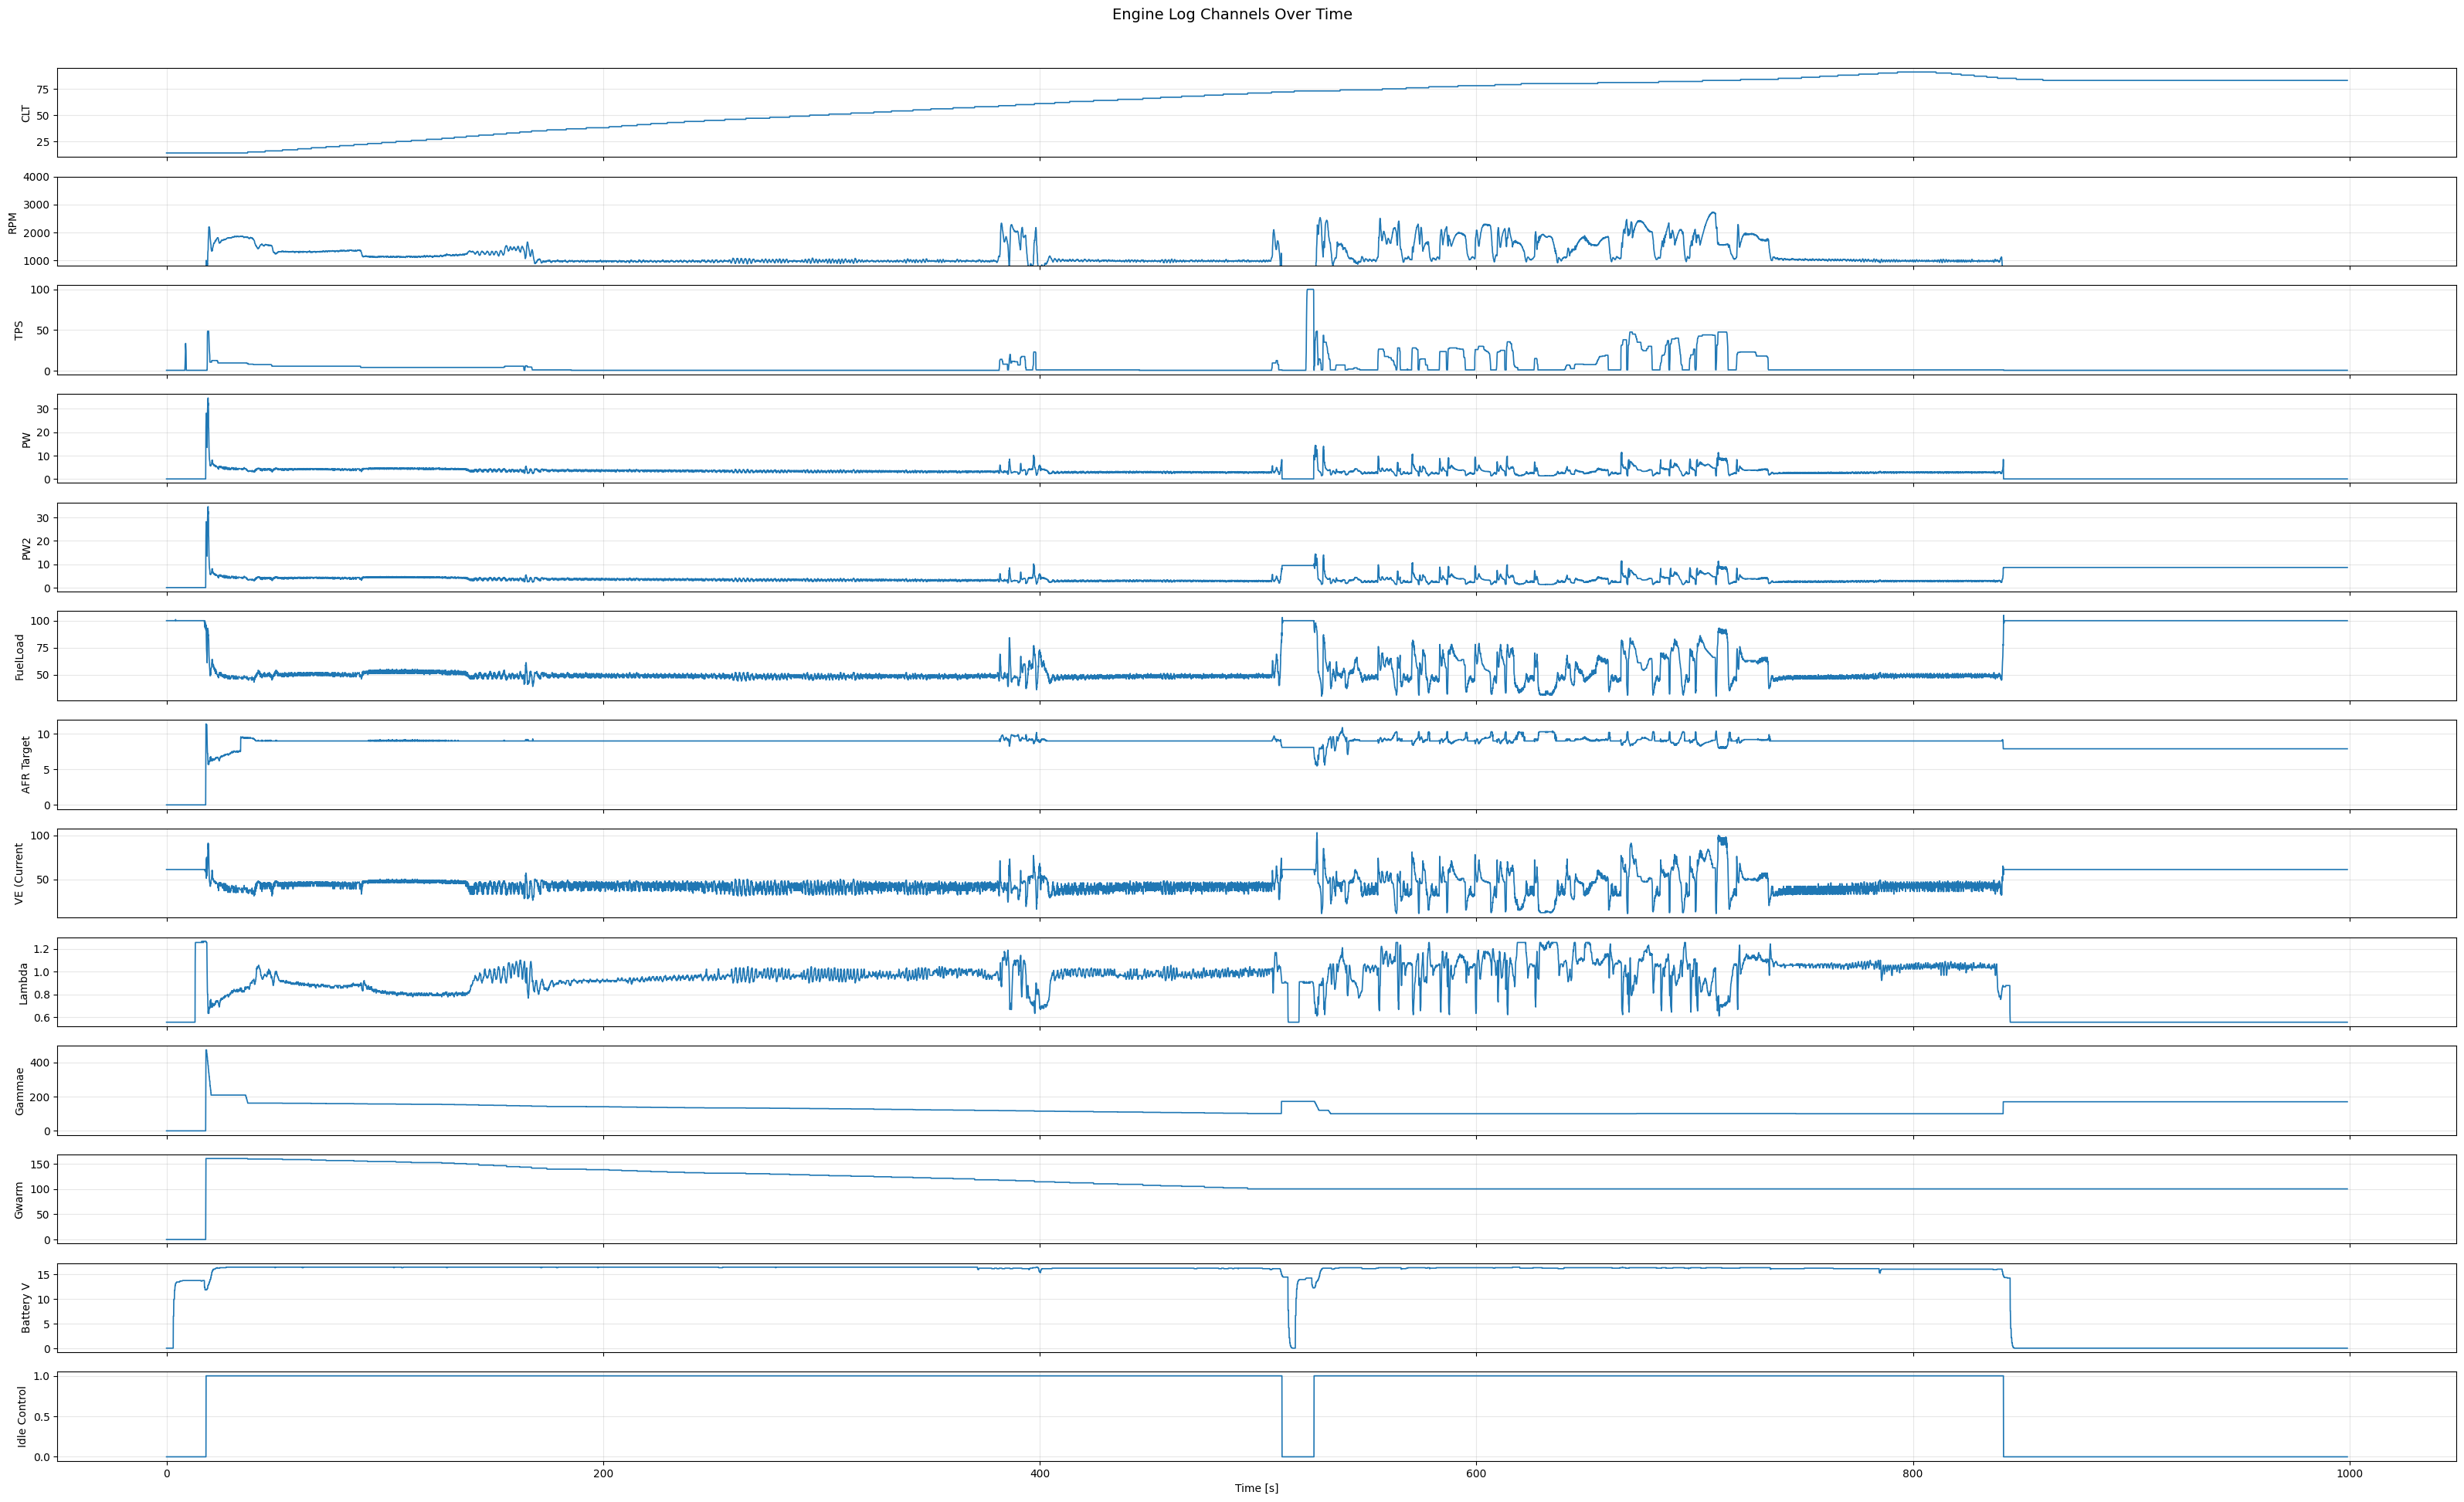

In [22]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

SHOW = False                       # True to pop up each figure

# Downsample/smooth options for huge logs (set both to None to disable)
DOWNSAMPLE_STEP = None    # e.g., 5  -> take every 5th row
ROLLING_WINDOW = None     # e.g., 5  -> rolling mean over 5 samples

# === LOAD ===
df = df_filtered

# Normalize time
t = pd.to_numeric(df["Time"], errors="coerce")
t = t - t.iloc[0]

# Define variables to plot (in order)
channels = [
    "CLT",
    "RPM",
    "TPS",
    "PW",
    "PW2",
    "FuelLoad",
    "AFR Target",
    "VE (Current",
    "Lambda",
    "Gammae",
    "Gwarm",
    "Battery V",
    "Idle Control"
]

# Filter only available ones
available = [c for c in channels if c in df.columns]
missing = [c for c in channels if c not in df.columns]
if missing:
    print("⚠️ Missing:", missing)

# === Plot all in one figure ===
n = len(available)
fig, axes = plt.subplots(n, 1, figsize=(32, 1.5 * n), sharex=True)
if n == 1:
    axes = [axes]  # ensure iterable if only one

for ax, col in zip(axes, available):
    ax.plot(t, df[col], linewidth=1.2)
    ax.set_ylabel(col)
    
    if col in ["RPM"]:
        ax.set_ylim(800, 4000)
    ax.grid(True, alpha=0.3)
    #ax.set_xlim(t.min(), t.max())

axes[-1].set_xlabel("Time [s]")
fig.suptitle("Engine Log Channels Over Time", fontsize=14, y=0.995)
plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.show()

In [34]:
for c in df_filtered.columns:
    if c in df_filtered.columns:
        df_filtered[c] = pd.to_numeric(df_filtered[c], errors="coerce")

/var/folders/xg/8flyksh91h501f6w253syw5m0000gn/T/ipykernel_37250/1673577858.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_filtered[c] = pd.to_numeric(df_filtered[c], errors="coerce")


In [37]:
df_filtered.columns

Index(['Time', 'SecL', 'RPM', 'MAP', 'MAPxRPM', 'TPS', 'AFR', 'Lambda', 'IAT',
       'CLT', 'Engine', 'DFCO', 'Gego', 'Gair', 'Gbattery', 'Gwarm', 'Gbaro',
       'Gammae', 'Accel Enrich', 'VE (Current', 'VE1', 'VE2', 'PW', 'PW2',
       'PW3', 'PW4', 'AFR Target', 'Lambda Target', 'Duty Cycle',
       'Duty Cycle (Staging', 'TPS DOT', 'Advance (Current', 'Dwell',
       'Dwell (Measured', 'Battery V', 'rpm/s', 'Boost PSI', 'Boost cut',
       'Hard Launch', 'Hard Limiter', 'Idle Control', 'IAC value',
       'Baro Pressure', 'Fan', 'Sync Loss #', 'Loops/s', 'Loops/rev', 'Aux0',
       'Aux1', 'Aux2', 'Aux3', 'Aux4', 'Aux5', 'Aux6', 'Aux7', 'Aux8', 'Aux9',
       'Aux10', 'Aux11', 'Aux12', 'Aux13', 'Aux14', 'Aux15', 'Advance 1',
       'Advance 2', 'FuelLoad', 'IgnitionLoad', 'Sync status',
       'Engine Prot. RPM', 'Engine Prot. CLT', 'Trip Meter Miles',
       'Odometer Miles', 'Vehicle Speed', 'Power', 'Torque'],
      dtype='object')